<a href="https://colab.research.google.com/github/RonazAbbasi/ml-zoomcamp2026/blob/main/Homework%204.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

QUESTION 1: ROC AUC
annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788
Highest AUC feature: lead_score

QUESTION 2: Validation AUC
Validation AUC: 0.732

QUESTION 3: Precision and Recall
Threshold where Precision and Recall are closest: 0.63

QUESTION 4: F1
Best F1 threshold: 0.41
Maximum F1: 0.758


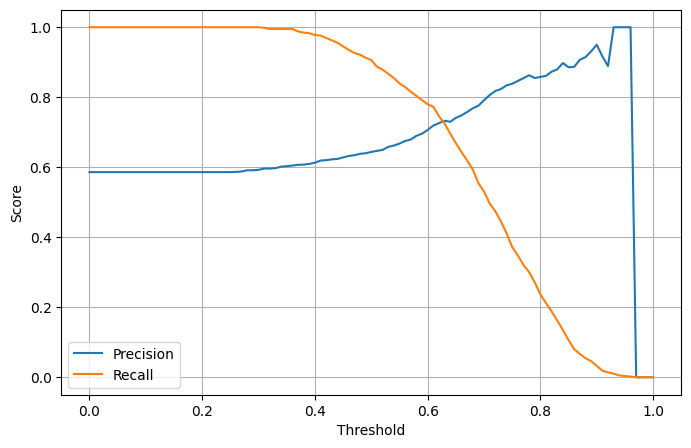


QUESTION 5: Five-fold Cross-validation
Fold AUC scores: [np.float64(0.731), np.float64(0.73), np.float64(0.736), np.float64(0.741), np.float64(0.721)]
Mean AUC: 0.732
Standard deviation: 0.007

QUESTION 6: Hyperparameter Tuning
C = 1e-06 | Mean AUC = 0.617 | Std = 0.019
C = 0.001 | Mean AUC = 0.749 | Std = 0.01
C = 1 | Mean AUC = 0.732 | Std = 0.007
Best C: 0.001


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train["converted"].values
y_val = df_val["converted"].values

print("QUESTION 1: ROC AUC")

auc_results = {}

for col in numerical:
    score = roc_auc_score(y_train, df_train[col])
    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[col])
    auc_results[col] = score
    print(col, round(score, 3))

print("Highest AUC feature:", max(auc_results, key=auc_results.get))

def prepare_features(data):
    return data[categorical + numerical].to_dict(orient="records")

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(prepare_features(df_train))
X_val = dv.transform(prepare_features(df_val))

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

print("\nQUESTION 2: Validation AUC")
print("Validation AUC:", round(roc_auc_score(y_val, y_pred), 3))

thresholds = np.arange(0.0, 1.01, 0.01)
precision_values = []
recall_values = []
f1_values = []

for threshold in thresholds:
    y_binary = (y_pred >= threshold).astype(int)
    precision_values.append(precision_score(y_val, y_binary, zero_division=0))
    recall_values.append(recall_score(y_val, y_binary, zero_division=0))
    f1_values.append(f1_score(y_val, y_binary, zero_division=0))

differences = [
    abs(p - r) if (p != 0 or r != 0) else float("inf")
    for p, r in zip(precision_values, recall_values)
]

intersection_idx = int(np.argmin(differences))
best_f1_idx = int(np.argmax(f1_values))

print("\nQUESTION 3: Precision and Recall")
print("Threshold where Precision and Recall are closest:", round(thresholds[intersection_idx], 2))

print("\nQUESTION 4: F1")
print("Best F1 threshold:", round(thresholds[best_f1_idx], 2))
print("Maximum F1:", round(f1_values[best_f1_idx], 3))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision_values, label="Precision")
plt.plot(thresholds, recall_values, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

print("\nQUESTION 5: Five-fold Cross-validation")

kf = KFold(n_splits=5, shuffle=True, random_state=1)
X_full = df_full_train[categorical + numerical]
y_full = df_full_train["converted"].values

cv_scores = []

for train_idx, val_idx in kf.split(X_full):
    fold_train = X_full.iloc[train_idx]
    fold_val = X_full.iloc[val_idx]
    y_fold_train = y_full[train_idx]
    y_fold_val = y_full[val_idx]

    dv_fold = DictVectorizer(sparse=True)
    X_fold_train = dv_fold.fit_transform(fold_train.to_dict(orient="records"))
    X_fold_val = dv_fold.transform(fold_val.to_dict(orient="records"))

    model_fold = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    model_fold.fit(X_fold_train, y_fold_train)

    fold_pred = model_fold.predict_proba(X_fold_val)[:, 1]
    cv_scores.append(roc_auc_score(y_fold_val, fold_pred))

print("Fold AUC scores:", [round(s, 3) for s in cv_scores])
print("Mean AUC:", round(np.mean(cv_scores), 3))
print("Standard deviation:", round(np.std(cv_scores), 3))

print("\nQUESTION 6: Hyperparameter Tuning")

C_values = [0.000001, 0.001, 1]
results = []

for C_value in C_values:
    scores = []

    for train_idx, val_idx in kf.split(X_full):
        fold_train = X_full.iloc[train_idx]
        fold_val = X_full.iloc[val_idx]
        y_fold_train = y_full[train_idx]
        y_fold_val = y_full[val_idx]

        dv_fold = DictVectorizer(sparse=True)
        X_fold_train = dv_fold.fit_transform(fold_train.to_dict(orient="records"))
        X_fold_val = dv_fold.transform(fold_val.to_dict(orient="records"))

        model_fold = LogisticRegression(solver="liblinear", C=C_value, max_iter=1000)
        model_fold.fit(X_fold_train, y_fold_train)

        fold_pred = model_fold.predict_proba(X_fold_val)[:, 1]
        scores.append(roc_auc_score(y_fold_val, fold_pred))

    mean_score = np.mean(scores)
    std_score = np.std(scores)
    results.append((C_value, mean_score, std_score))

    print("C =", C_value, "| Mean AUC =", round(mean_score, 3), "| Std =", round(std_score, 3))

best_result = sorted(results, key=lambda x: (-x[1], x[2], x[0]))[0]
print("Best C:", best_result[0])